Project question: What drives success for teams in the FIFA world cup and what factors influence match outcomes?

Import packages


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from matplotlib.colors import ListedColormap

Load raw data

In [19]:
# Results from 1872 - 2026
df = pd.read_csv(r'C:\Users\bevamin\OneDrive - Capgemini\Documents\fifa-project\data\International_football_results_1872_to_2026/results.csv')

Summary statistics

In [20]:
df.head()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0.0,0.0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4.0,2.0,Friendly,London,England,False
2,1874-03-07,Scotland,England,2.0,1.0,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2.0,2.0,Friendly,London,England,False
4,1876-03-04,Scotland,England,3.0,0.0,Friendly,Glasgow,Scotland,False


In [21]:
df.tail()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49500,2026-07-07,Switzerland,Colombia,0.0,0.0,FIFA World Cup,Vancouver,Canada,True
49501,2026-07-09,France,Morocco,NaN,NaN,FIFA World Cup,Foxborough,United States,True
49502,2026-07-10,Spain,Belgium,NaN,NaN,FIFA World Cup,Inglewood,United States,True
49503,2026-07-11,Norway,England,NaN,NaN,FIFA World Cup,Miami Gardens,United States,True
49504,2026-07-11,Argentina,Switzerland,NaN,NaN,FIFA World Cup,Kansas City,United States,True


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49505 entries, 0 to 49504
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        49505 non-null  str    
 1   home_team   49505 non-null  str    
 2   away_team   49505 non-null  str    
 3   home_score  49501 non-null  float64
 4   away_score  49501 non-null  float64
 5   tournament  49505 non-null  str    
 6   city        49505 non-null  str    
 7   country     49505 non-null  str    
 8   neutral     49505 non-null  bool   
dtypes: bool(1), float64(2), str(6)
memory usage: 3.1 MB


In [23]:
df.describe()

,home_score,away_score
count,49501.000000,49501.000000
mean,1.757197,1.181936
std,1.773821,1.401655
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,31.000000,21.000000


In [24]:
df.count()

date          49505
home_team     49505
away_team     49505
home_score    49501
away_score    49501
tournament    49505
city          49505
country       49505
neutral       49505
dtype: int64

In [25]:
df.shape

(49505, 9)

<Axes: title={'center': 'Top 10 Home Teams with Most Scores'}, xlabel='home_team', ylabel='Total Home Scores'>

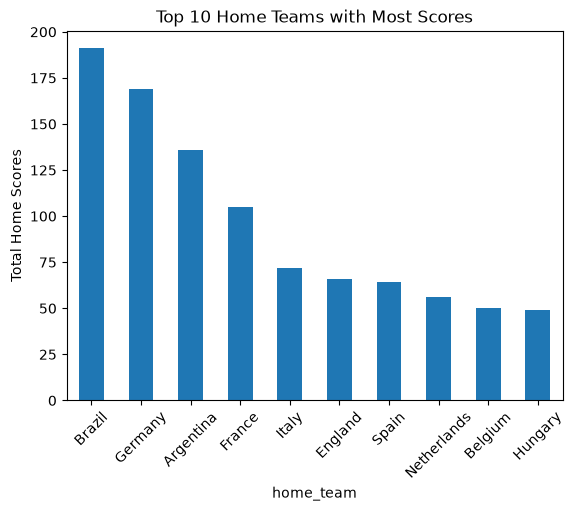

In [26]:
# team with most home or away scores

# home team with most scores where tournament is FIFA World Cup
df[df['tournament'] == 'FIFA World Cup'].groupby('home_team')['home_score'].sum().sort_values(ascending=False).head(10).plot(kind='bar', title='Top 10 Home Teams with Most Scores', rot=45, ylabel = 'Total Home Scores')

<Axes: title={'center': 'Top 10 Away Teams with Most Scores'}, xlabel='away_team', ylabel='Total Away Scores'>

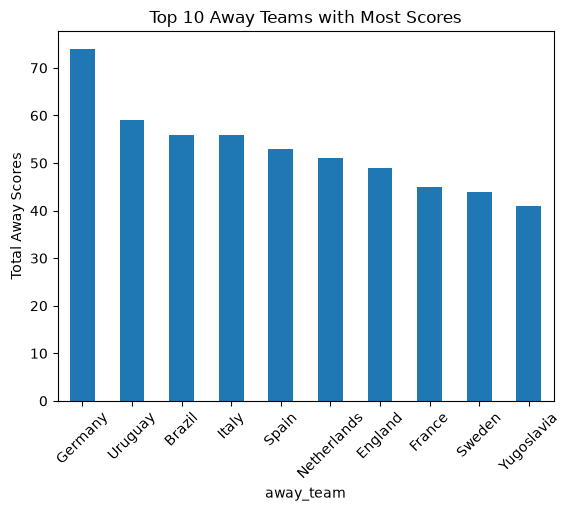

In [27]:
# away team with most scores where tournament is FIFA World Cup
df[df['tournament'] == 'FIFA World Cup'].groupby('away_team')['away_score'].sum().sort_values(ascending=False).head(10).plot(kind='bar', title='Top 10 Away Teams with Most Scores', rot=45, ylabel = 'Total Away Scores')

home_team
Brazil         79.0
Germany        70.0
Argentina      52.0
Italy          45.0
France         44.0
England        36.0
Spain          35.0
Netherlands    32.0
Uruguay        25.0
Belgium        24.0
dtype: float64
[79. 70. 52. 45. 44. 36. 35. 32. 25. 24.]
Index(['Brazil', 'Germany', 'Argentina', 'Italy', 'France', 'England', 'Spain',
       'Netherlands', 'Uruguay', 'Belgium'],
      dtype='str', name='home_team')


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Brazil'),
  Text(1, 0, 'Germany'),
  Text(2, 0, 'Argentina'),
  Text(3, 0, 'Italy'),
  Text(4, 0, 'France'),
  Text(5, 0, 'England'),
  Text(6, 0, 'Spain'),
  Text(7, 0, 'Netherlands'),
  Text(8, 0, 'Uruguay'),
  Text(9, 0, 'Belgium')])

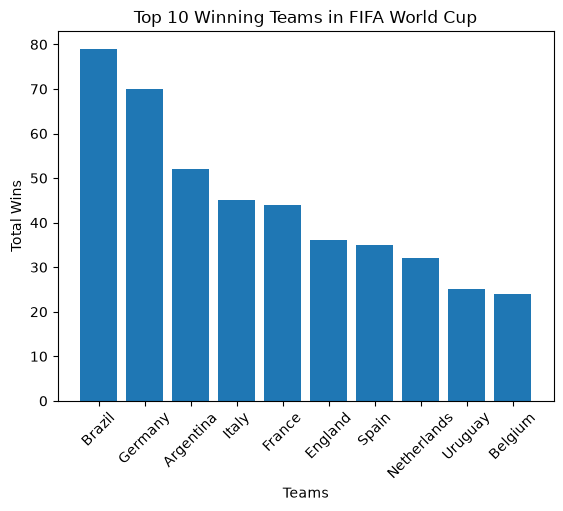

In [41]:
# highest scoring team overall
# remove the rows where tournament is not FIFA World Cup

fifa_only_df = df[df['tournament'] == 'FIFA World Cup']
# overall_top_scorer_home = fifa_only_df.groupby('home_team')['home_score'].max()
# overall_top_scorer_away = fifa_only_df.groupby('away_team')['away_score'].max()
# print(overall_top_scorer_home)
# print(overall_top_scorer_away)


# i need the team that won the most over time, so need to calculate total wins by doing their home-score - away depending on where they played
winning_team = fifa_only_df.copy()
winning_team['home_win'] = winning_team['home_score'] > winning_team['away_score']
winning_team['away_win'] = winning_team['away_score'] > winning_team['home_score']

winning_team_overall = winning_team.groupby('home_team')['home_win'].sum() + winning_team.groupby('away_team')['away_win'].sum()
print(winning_team_overall.sort_values(ascending=False).head(10))

winners_list = winning_team_overall.sort_values(ascending=False).head(10)
print((winners_list.values))
print((winners_list.index))

plt.bar(winners_list.index, winners_list.values)
plt.title('Top 10 Winning Teams in FIFA World Cup')
plt.ylabel('Total Wins')
plt.xlabel('Teams')
plt.xticks(rotation=45)




8
<class 'numpy.ndarray'>
[Timestamp('1942-12-31 00:00:00'), Timestamp('1954-12-31 00:00:00'), Timestamp('1966-12-31 00:00:00'), Timestamp('1978-12-31 00:00:00'), Timestamp('1990-12-31 00:00:00'), Timestamp('2002-12-31 00:00:00'), Timestamp('2014-12-31 00:00:00'), Timestamp('2026-07-11 00:00:00')]


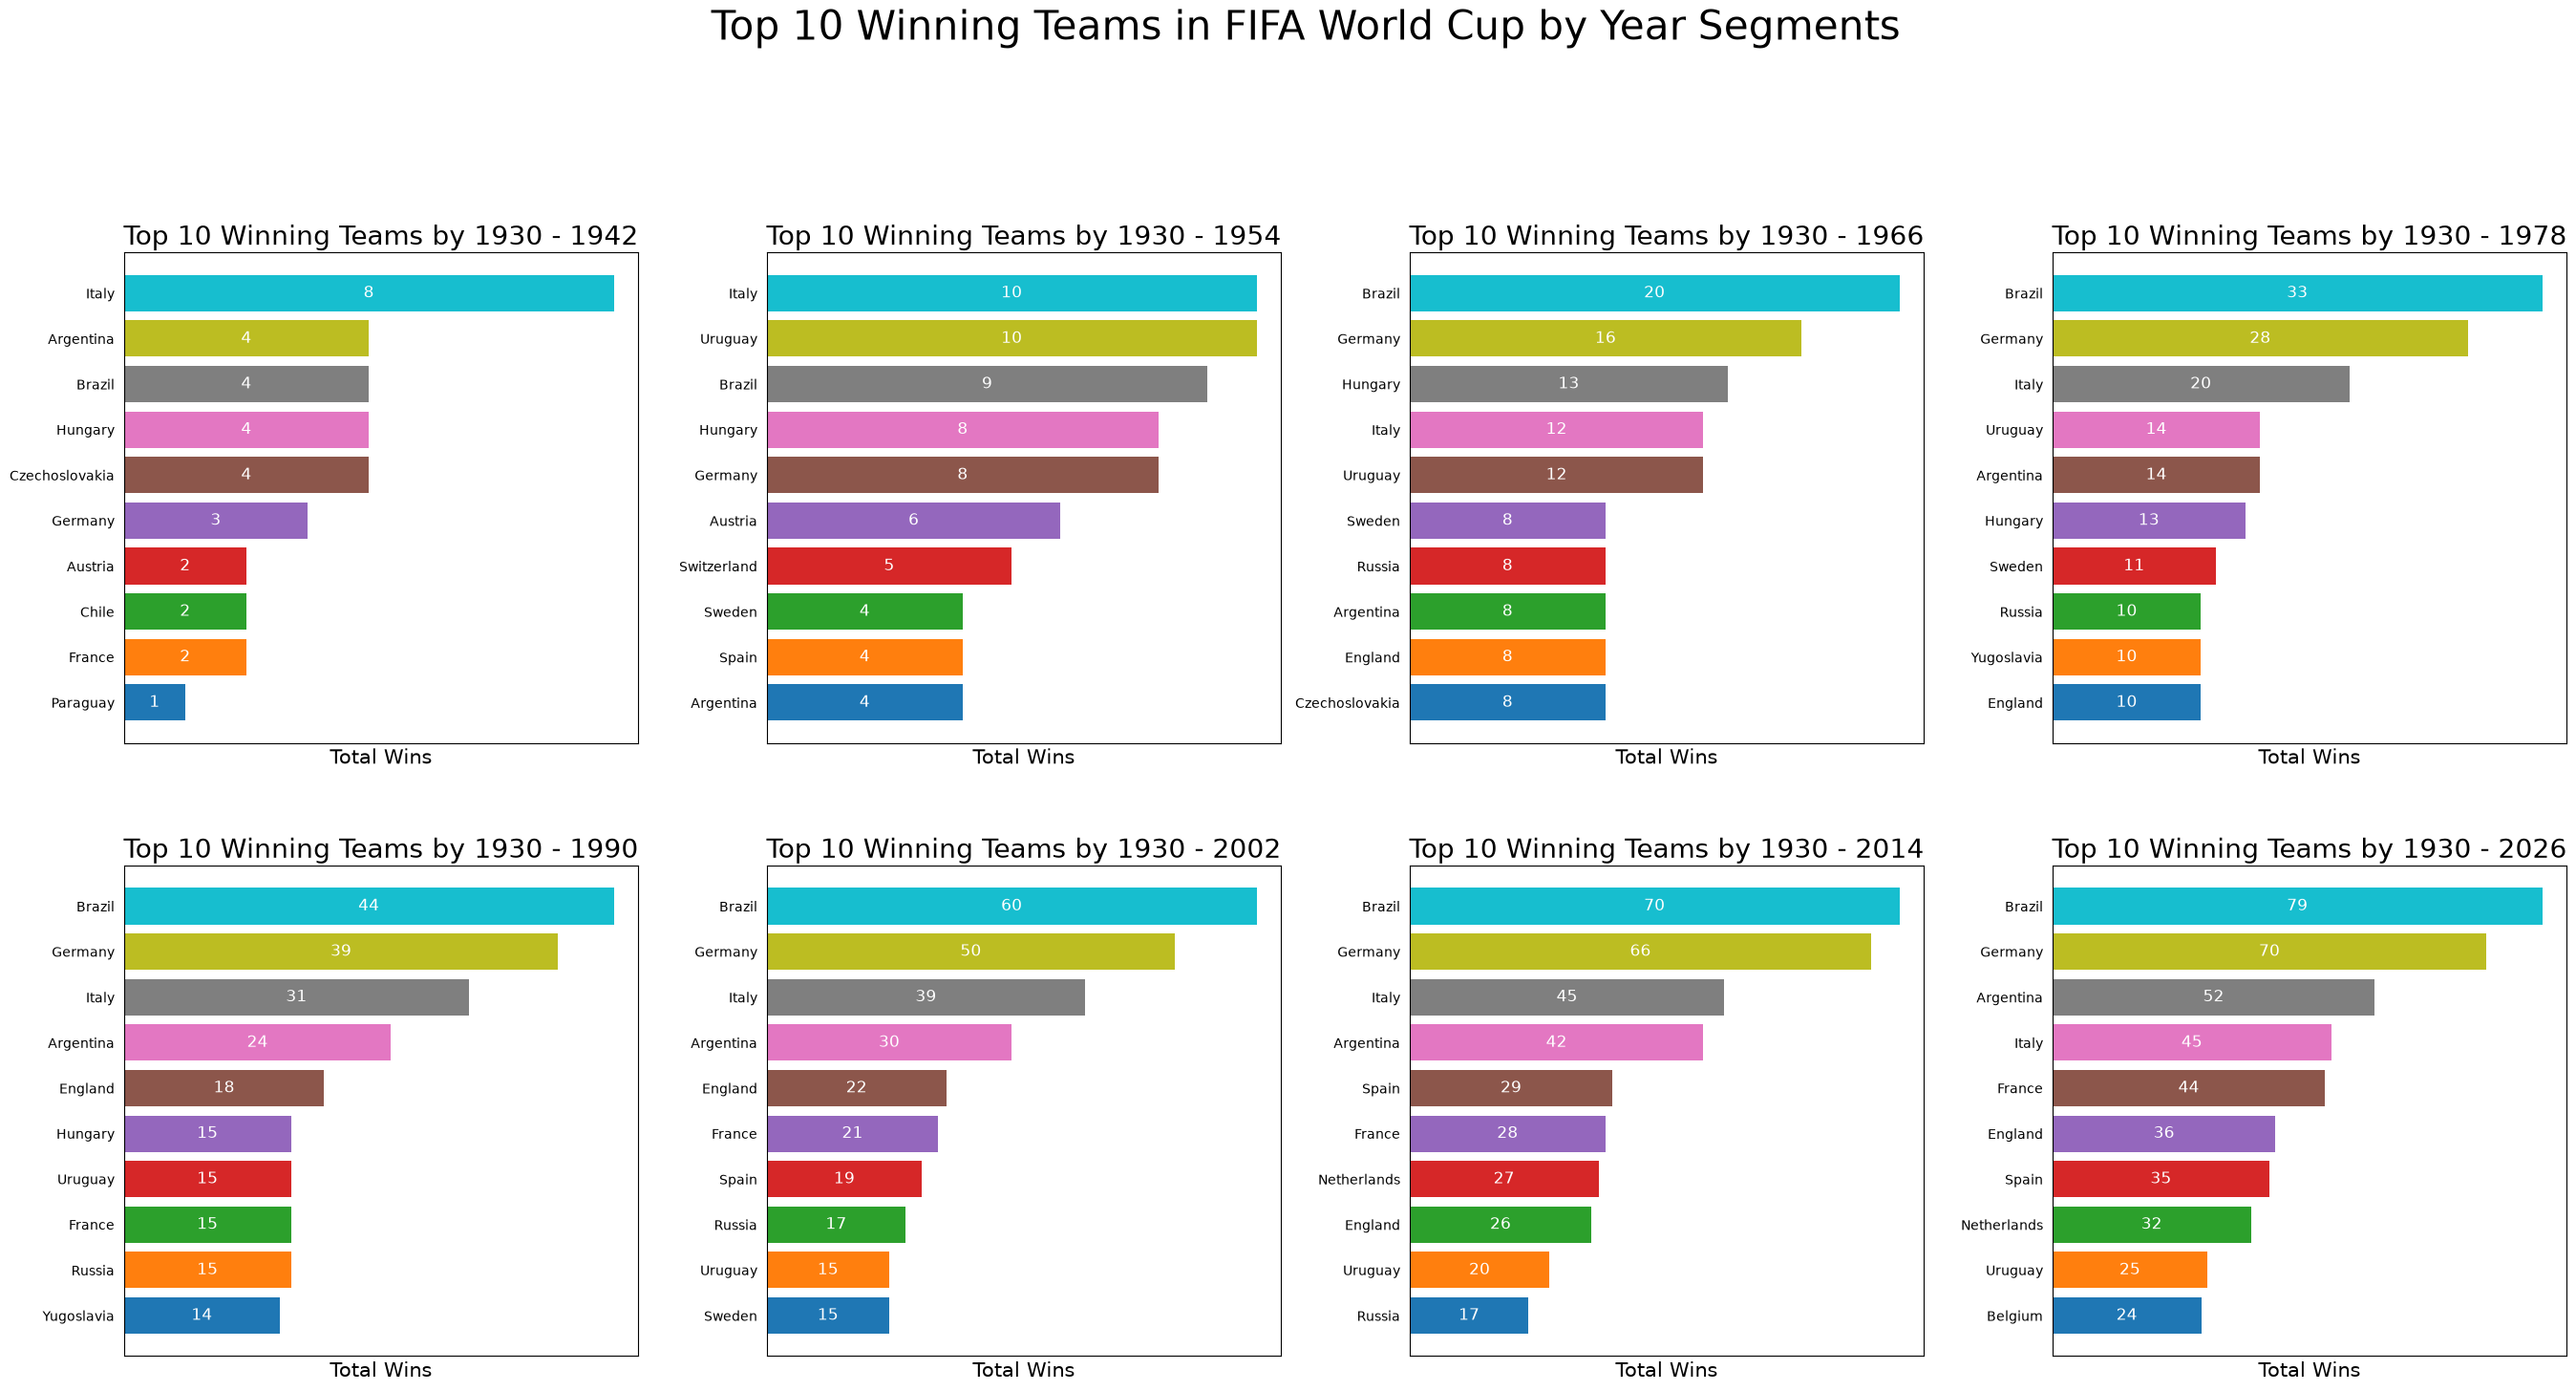

In [144]:
# SPLIT BY EVERY 20 YRS

#date from str to date
winning_team['date'] = pd.to_datetime(winning_team['date'], format='%Y-%m-%d')


earliest_date = winning_team.date.min()
latest_date = winning_team.date.max()

no_of_segments = (latest_date.year - earliest_date.year) // 12
print(no_of_segments)

fig, ax = plt.subplots(2, 4, figsize = (33, 15))
print(type(ax))

timepoints = [date for date in pd.date_range(start=earliest_date, end=latest_date, freq='12YE')]
timepoints.pop(0)
timepoints.append(latest_date)
print(timepoints)

flattened_ax = ax.flatten()

for n, date in enumerate(timepoints):
    filtered_df = winning_team[winning_team['date'] < date]
    current_ax = flattened_ax[n]
    winning_team_overall = filtered_df.groupby('home_team')['home_win'].sum() + filtered_df.groupby('away_team')['away_win'].sum()
    winners_list = winning_team_overall.sort_values(ascending=False).head(10)
    winners_list.sort_values(ascending=True, inplace=True)
    p = current_ax.barh(winners_list.index, winners_list.values, color = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan'])
    fig.suptitle('Top 10 Winning Teams in FIFA World Cup by Year Segments', fontsize=30, y=1.05)
    current_ax.set_title(f'Top 10 Winning Teams by {earliest_date.year} - {date.year}', fontsize=20)
    current_ax.set_yticks(range(10))
    current_ax.set_xlabel('Total Wins', fontsize=15)
    current_ax.tick_params(axis='y', left=False)
    current_ax.tick_params(axis='x', bottom=False, labelbottom=False)
    current_ax.bar_label(p, label_type='center', fmt='%d', fontsize=12, color='white')
    #fig.tight_layout()
    fig.subplots_adjust(hspace=0.25, wspace=0.25)



actual fifa tournament winners every world cup

In [ ]:
df2 = pd.read_csv(r'C:\Users\bevamin\OneDrive - Capgemini\Documents\fifa-project\data\world_cup_complete_dataset\wc_all_matches.csv')

In [3]:
df2.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes
0,1930,Group Stage,France,4,1,Mexico,Estadio Centenario,Montevideo,Uruguay,1930-07-13,First ever WC match
1,1930,Group Stage,USA,3,0,Belgium,Estadio Centenario,Montevideo,Uruguay,1930-07-13,NaN
2,1930,Group Stage,Yugoslavia,2,1,Brazil,Estadio Centenario,Montevideo,Uruguay,1930-07-14,NaN
3,1930,Group Stage,Uruguay,1,0,Peru,Estadio Centenario,Montevideo,Uruguay,1930-07-18,NaN
4,1930,Group Stage,Argentina,6,3,USA,Estadio Centenario,Montevideo,Uruguay,1930-07-26,NaN


In [4]:
df2.tail()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes
179,2022,Quarter-final,France,2,1,England,Al Bayt Stadium,Al Khor,Qatar,2022-12-10,Kane pen miss
180,2022,Semi-final,Argentina,3,0,Croatia,Lusail Stadium,Lusail,Qatar,2022-12-13,Messi pen + Álvarez 2
181,2022,Semi-final,France,2,0,Morocco,Al Bayt Stadium,Al Khor,Qatar,2022-12-14,NaN
182,2022,3rd Place,Croatia,2,1,Morocco,Khalifa International,Al Rayyan,Qatar,2022-12-17,NaN
183,2022,Final,Argentina,3,3,France,Lusail Stadium,Lusail,Qatar,2022-12-18,AET - Argentina win 4-2 pens - GOAT final


In [7]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 11 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   year     184 non-null    int64
 1   stage    184 non-null    str  
 2   team1    184 non-null    str  
 3   score1   184 non-null    int64
 4   score2   184 non-null    int64
 5   team2    184 non-null    str  
 6   venue    184 non-null    str  
 7   city     184 non-null    str  
 8   country  184 non-null    str  
 9   date     184 non-null    str  
 10  notes    102 non-null    str  
dtypes: int64(3), str(8)
memory usage: 15.9 KB


In [31]:
# match winner is whichever team had highest score. added match winner column to df2

df2['match_winner'] = df2.apply(lambda x: x['team1'] if x['score1'] > x['score2'] else (x['team2'] if x['score2'] > x['score1'] else 'Draw'), axis=1)
# print(df2[['year', 'team1', 'team2', 'score1', 'score2', 'match_winner']])
df2.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
0,1930,Group Stage,France,4,1,Mexico,Estadio Centenario,Montevideo,Uruguay,1930-07-13,First ever WC match,France
1,1930,Group Stage,USA,3,0,Belgium,Estadio Centenario,Montevideo,Uruguay,1930-07-13,NaN,USA
2,1930,Group Stage,Yugoslavia,2,1,Brazil,Estadio Centenario,Montevideo,Uruguay,1930-07-14,NaN,Yugoslavia
3,1930,Group Stage,Uruguay,1,0,Peru,Estadio Centenario,Montevideo,Uruguay,1930-07-18,NaN,Uruguay
4,1930,Group Stage,Argentina,6,3,USA,Estadio Centenario,Montevideo,Uruguay,1930-07-26,NaN,Argentina


In [35]:
# filtered df to show only finals matches
finals_df = df2[(df2['stage'] == 'Final')]
finals_df.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
7,1930,Final,Uruguay,4,2,Argentina,Estadio Centenario,Montevideo,Uruguay,1930-07-30,First WC Final,Uruguay
14,1934,Final,Italy,2,1,Czechoslovakia,PNF Stadium,Rome,Italy,1934-06-10,AET,Italy
21,1938,Final,Italy,4,2,Hungary,Stade de Colombes,Paris,France,1938-06-19,NaN,Italy
33,1954,Final,West Germany,3,2,Hungary,Wankdorf,Bern,Switzerland,1954-07-04,Miracle of Bern,West Germany
40,1958,Final,Brazil,5,2,Sweden,Råsunda,Stockholm,Sweden,1958-06-29,Pelé scores 2 at 17,Brazil


In [ ]:
# some match winners results are Draw, so need to check notes to see who actually won, eg if it went to penalties

finals_with_notes = finals_df[finals_df['match_winner'] == 'Draw'] 
finals_with_notes.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
106,1994,Final,Brazil,0,0,Italy,Rose Bowl,Pasadena,USA,1994-07-17,Brazil win 3-2 pens - Baggio misses,Draw
135,2006,Final,Italy,1,1,France,Olympiastadion,Berlin,Germany,2006-07-09,Zidane headbutt - Italy win 5-3 pens,Draw
183,2022,Final,Argentina,3,3,France,Lusail Stadium,Lusail,Qatar,2022-12-18,AET - Argentina win 4-2 pens - GOAT final,Draw


In [ ]:
# based on above, need to change match winner column for those specific matches to reflect actual winner.
df2.loc[106, 'match_winner'] = 'Brazil'
df2.loc[135, 'match_winner'] = 'Italy'
df2.loc[183, 'match_winner'] = 'Argentina'

#code to check that results were changed
df2.loc[[106, 135, 183]]

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
106,1994,Final,Brazil,0,0,Italy,Rose Bowl,Pasadena,USA,1994-07-17,Brazil win 3-2 pens - Baggio misses,Brazil
135,2006,Final,Italy,1,1,France,Olympiastadion,Berlin,Germany,2006-07-09,Zidane headbutt - Italy win 5-3 pens,Italy
183,2022,Final,Argentina,3,3,France,Lusail Stadium,Lusail,Qatar,2022-12-18,AET - Argentina win 4-2 pens - GOAT final,Argentina


In [46]:
# team who won the most world cups:
world_cup_winners = df2[df2['stage'] == 'Final'].groupby('match_winner').agg(years=('year', list), count=('year', 'count')).sort_values(by='count', ascending=False)
world_cup_winners

,years,count
match_winner,,
Brazil,"[1958, 1962, 1970, 1994, 2002]",5
Italy,"[1934, 1938, 1982, 2006]",4
Argentina,"[1978, 1986, 2022]",3
West Germany,"[1954, 1974, 1990]",3
France,"[1998, 2018]",2
Germany,[2014],1
England,[1966],1
Spain,[2010],1
Uruguay,[1930],1


how far teams got throughout tournament, ie not necessarily won the cup, but progressed well with good stats